In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')

import warnings
warnings.filterwarnings("ignore")

from sklearn.feature_selection import mutual_info_regression

#### Feature Variance Analysis
基于金融学中的波动共振概念，我决定从特征方差与目标变量(`market_forward_excess_returns`)方差的关系来判断特征对市场状态的敏感性。如果特征的波动性变化与目标的波动性变化同步，那么说明这些特征对市场波动变化是有反应的，并且可以作为后续进一步特征筛选或 regime detection 的依据。  

每个特征的方差 vs target 的方差

先计算滚动方差，然后再对每一个特征进行标准化处理。  
目标变量的方差（波动性）是衡量的基准，需要保持其原有的、真实的含义，所以不进行标准化处理。  
这样就能做到用一个保持原始经济意义的基准（市场波动性），去衡量经过统一尺度处理后的不同特征的相对波动响应。  

注意：如果用StandardScalar在整个训练集的特征列进行标准化（`fit_transform`）会引入未来信息、造成数据泄露。  
所以在这里我们使用滚动标准化，这和计算方差的时候使用的滚动方差思想一致。

同时我们要对 target variable 进行 lag 处理，不然会有数据泄露。

In [2]:
clean_df = pd.read_csv('clean_train.csv')
clean_df.head()

,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V2,V3,V4,V5,V6,V7,V8,forward_returns,risk_free_rate,target
0,1006,0,0,0,1,0,-1,0,0,0,...,0.986772,0.970899,0.986111,0.0,0.000661,0.0,0.000661,-0.000669,0.000121,-0.001100
1,1007,0,0,0,1,0,-1,0,0,0,...,0.984788,0.972884,0.984788,0.0,0.000661,0.0,0.000661,0.005348,0.000121,0.004917
2,1008,0,0,0,1,0,-1,0,0,0,...,0.982143,0.834656,0.983466,0.0,0.000661,0.0,0.000661,0.001996,0.000121,0.001565
3,1009,0,0,0,1,0,-1,0,0,0,...,0.980159,0.928571,0.979497,0.0,0.000661,0.0,0.000661,-0.001327,0.000121,-0.001758
4,1010,0,0,0,1,0,0,0,1,0,...,1.000000,0.997354,1.000000,0.0,0.000661,0.0,0.000661,-0.003987,0.000119,-0.004415


In [3]:
M_cols = [c for c in clean_df.columns if c.startswith('M')]
E_cols = [c for c in clean_df.columns if c.startswith('E')]
I_cols = [c for c in clean_df.columns if c.startswith('I')]
P_cols = [c for c in clean_df.columns if c.startswith('P')]
V_cols = [c for c in clean_df.columns if c.startswith('V')]
S_cols = [c for c in clean_df.columns if c.startswith('S')]

groups = {
    "Market Dynamics (M*)": M_cols,
    "Macro Economic (E*)": E_cols,
    "Interest Rate (I*)": I_cols,
    "Price/Valuation (P*)": P_cols,
    "Volatility (V*)": V_cols,
    "Sentiment (S*)": S_cols,
}

features = M_cols + E_cols + I_cols + P_cols + V_cols + S_cols

print('We have a total of {} features excluding date_id, binary features, forward_returns, risk_free_rate and the target variable.'.format(len(features)))

We have a total of 76 features excluding date_id, binary features, forward_returns, risk_free_rate and the target variable.


In [4]:
WINDOW = 126  # 126天（大约半年）滚动窗口

# 计算所选特征的滚动方差（不含 date_id, binary features, forward_returns, risk_free_rate and the target variable）
feature_var = clean_df[features].rolling(window=WINDOW).var()

# 单独计算 lagged target的滚动方差
clean_df['lagged_target'] = clean_df['target'].shift(1)
lagged_target_var = clean_df['lagged_target'].rolling(WINDOW).var().rename('lagged_target_var')

**下面对所选特征进行滚动标准化处理**

In [5]:
feature_var_mean = feature_var.rolling(window=WINDOW).mean()
feature_var_std = feature_var.rolling(window=WINDOW).std()
standardized_feature_var = (feature_var - feature_var_mean) / (feature_var_std + 1e-9)  # 防止分母为 0 导致结果出现 inf 值
standardized_feature_var

,M10,M11,M12,M15,M16,M17,M18,M2,M3,M4,...,S1,S10,S11,S2,S4,S5,S6,S7,S8,S9
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7979,-0.848131,-0.667881,-1.093577,0.706842,0.523539,-1.801159,-0.469103,-0.189701,0.319403,-0.023087,...,-0.579082,-0.163214,-1.447010,0.267557,-1.223683,1.230375,0.092367,-1.748642,-0.102930,2.274383
7980,-0.772238,-0.682383,-1.093506,0.658568,0.608638,-1.773418,-0.563374,-0.202139,0.030726,-0.057555,...,-0.543536,0.225136,-1.361160,0.094374,-1.214728,1.211611,0.169383,-1.753811,-0.098419,2.254043
7981,-0.703049,-0.715183,-1.104894,0.614771,0.671627,-1.745243,-0.658147,-0.509477,0.021805,-0.150477,...,-0.488650,0.389394,-1.302293,-0.094685,-1.203102,1.189659,0.246372,-1.759185,-0.113421,1.773245
7982,-0.640776,-0.733767,-1.110329,0.587417,0.720814,-1.717234,-0.753223,-0.610601,0.019632,-0.248430,...,-0.421260,0.780734,-1.140782,-0.321029,-0.969451,1.169022,0.305303,-1.764772,-0.129929,2.093944


In [6]:
# 检查 standardized_feature_var 中每列的 NaN 总数
nan_counts = standardized_feature_var.isna().sum()

print('Number of NaNs in each feature of standardized_feature_var:')
print(nan_counts[nan_counts > 0])

# 检查是否有 inf
inf_counts = np.isinf(standardized_feature_var).sum()
print('\nNumber of Infs in each feature of standardized_feature_var:')
print(inf_counts[inf_counts > 0])

Number of NaNs in each feature of standardized_feature_var:
M10    250
M11    250
M12    250
M15    250
M16    250
      ... 
S5     250
S6     250
S7     250
S8     250
S9     250
Length: 76, dtype: int64

Number of Infs in each feature of standardized_feature_var:
Series([], dtype: int64)


**注意这里发现每个特征在进行滚动标准化之后会出现 250 个 NaNs**   
**这是应该的，因为在计算滚动方差的时候一开始有 125 个 NaNs，然后接着计算滚动平均值的时候又出现了 125 个 NaNs**

**先计算 Sample Pearson Correlation Coefficient 看特征波动性与市场波动性之间的线性相关程度**

In [7]:
vol_resonance_score = standardized_feature_var.corrwith(lagged_target_var)
vol_resonance_score = vol_resonance_score.sort_values(ascending=False)

print('Linear volatility resonance score of selected features and the target:', '\n')
print(vol_resonance_score)

Linear volatility resonance score of selected features and the target: 

M2     0.292960
P7     0.244885
M9     0.215118
I1     0.185857
M4     0.183991
         ...   
P4    -0.133150
I3    -0.146826
P12   -0.196093
P5    -0.196929
P1    -0.200176
Length: 76, dtype: float64


In [8]:
print(vol_resonance_score[(vol_resonance_score.isna())])
print(vol_resonance_score[np.isinf(vol_resonance_score)])

Series([], dtype: float64)
Series([], dtype: float64)


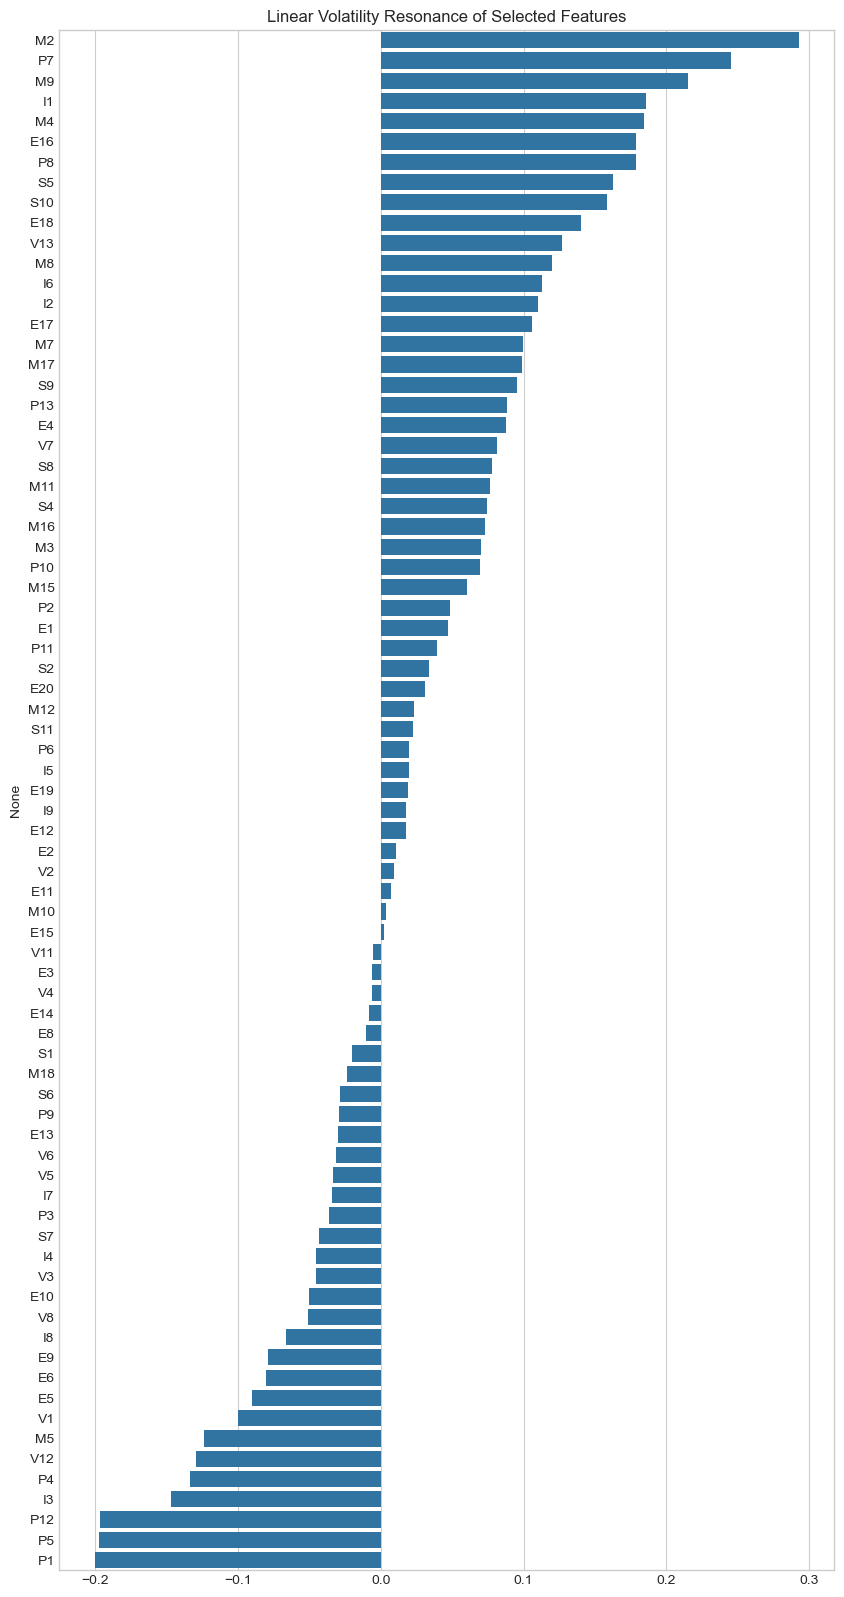

In [9]:
plt.figure(figsize=(10, 20))
sns.barplot(y=vol_resonance_score.index, x=vol_resonance_score.values)
plt.title("Linear Volatility Resonance of Selected Features")
plt.show()

**再计算 Mutual Information 看特征波动性与市场波动性之间的非线性相关程度**

In [10]:
print('Are all selected features of float data type (continuous features)?')
if (clean_df[features].dtypes == 'float').all() == True:
    print('Yes')

Are all selected features of float data type (continuous features)?
Yes


In [11]:
def make_mi_scores(X, y, discrete_features=None):
    mi_scores = mutual_info_regression(X, y, discrete_features=discrete_features)
    mi_scores = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)
    return mi_scores

In [12]:
# 将特征方差和 target 方差按列合并
var_df = pd.concat([standardized_feature_var, lagged_target_var], axis=1)
var_df

,M10,M11,M12,M15,M16,M17,M18,M2,M3,M4,...,S10,S11,S2,S4,S5,S6,S7,S8,S9,lagged_target_var
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7979,-0.848131,-0.667881,-1.093577,0.706842,0.523539,-1.801159,-0.469103,-0.189701,0.319403,-0.023087,...,-0.163214,-1.447010,0.267557,-1.223683,1.230375,0.092367,-1.748642,-0.102930,2.274383,0.000139
7980,-0.772238,-0.682383,-1.093506,0.658568,0.608638,-1.773418,-0.563374,-0.202139,0.030726,-0.057555,...,0.225136,-1.361160,0.094374,-1.214728,1.211611,0.169383,-1.753811,-0.098419,2.254043,0.000139
7981,-0.703049,-0.715183,-1.104894,0.614771,0.671627,-1.745243,-0.658147,-0.509477,0.021805,-0.150477,...,0.389394,-1.302293,-0.094685,-1.203102,1.189659,0.246372,-1.759185,-0.113421,1.773245,0.000132
7982,-0.640776,-0.733767,-1.110329,0.587417,0.720814,-1.717234,-0.753223,-0.610601,0.019632,-0.248430,...,0.780734,-1.140782,-0.321029,-0.969451,1.169022,0.305303,-1.764772,-0.129929,2.093944,0.000132


In [13]:
# 在计算 MI 之前需要先删除任何包含 NaNs 的行
print(f"Shape before dropping NaNs: {var_df.shape}")
var_df_clean = var_df.dropna()
print(f"Shape after dropping NaNs:  {var_df_clean.shape}")

# 重新分离出特征方差（X）和 target 方差（y）
X = var_df_clean.drop('lagged_target_var', axis=1)
y = var_df_clean['lagged_target_var']

# 计算互信息
mi_scores = make_mi_scores(X, y, discrete_features=False)

print('Non-linear volatility resonance of selected features and the target:\n')
print(mi_scores)

Shape before dropping NaNs: (7984, 77)
Shape after dropping NaNs:  (7734, 77)
Non-linear volatility resonance of selected features and the target:

P6     0.755081
S5     0.720086
P5     0.703947
E20    0.700458
P12    0.695278
         ...   
V8     0.449586
V11    0.358894
M16    0.314942
P3     0.247834
P4     0.235306
Length: 76, dtype: float64


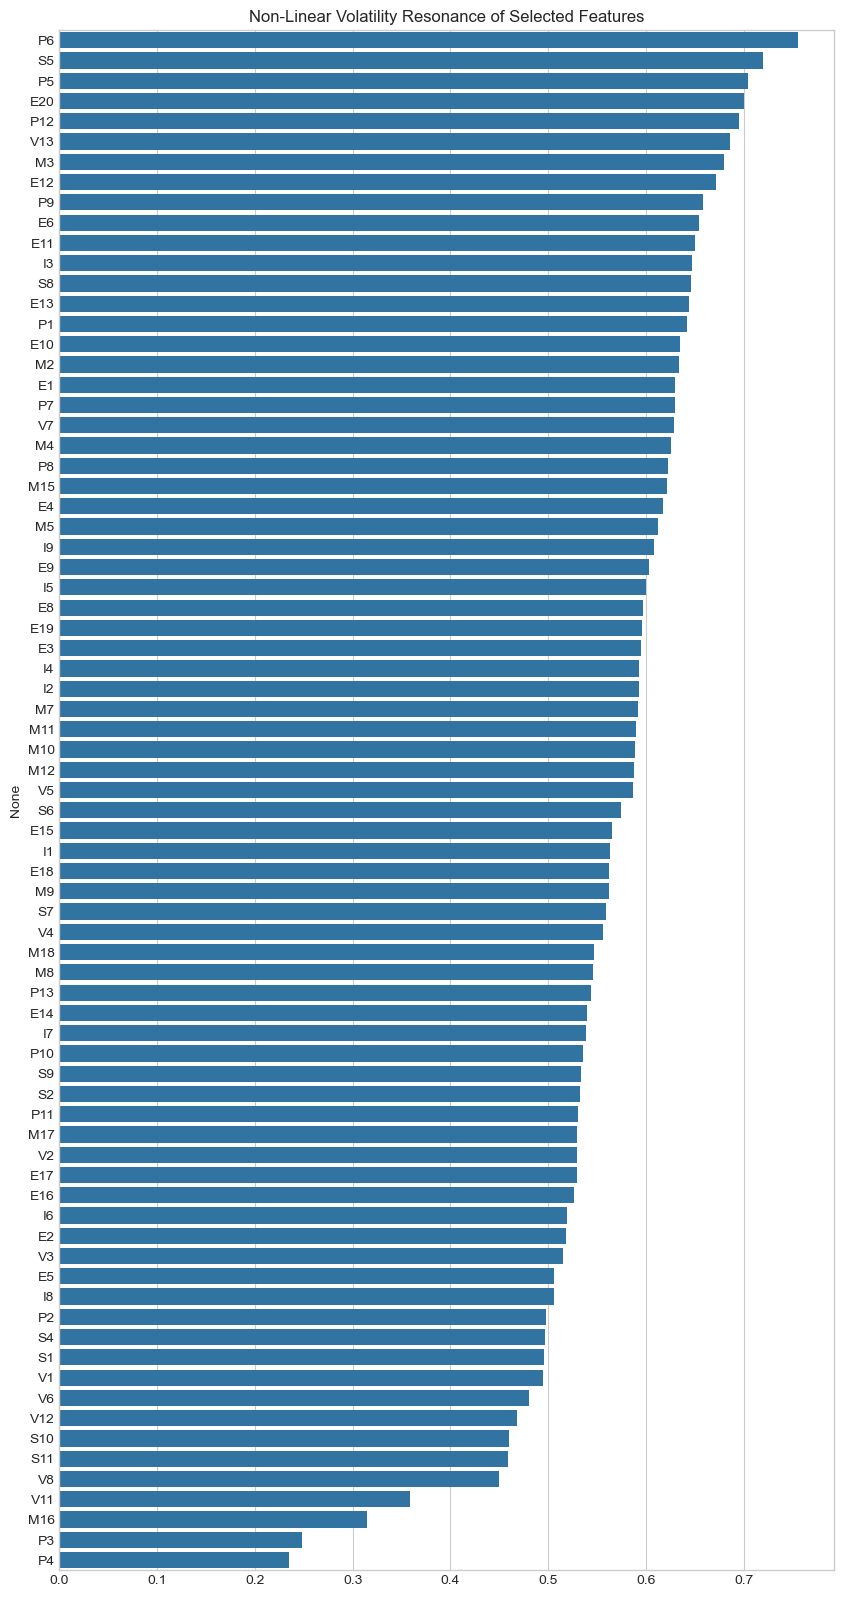

In [14]:
plt.figure(figsize=(10, 20))
sns.barplot(y=mi_scores.index, x=mi_scores.values)
plt.title("Non-Linear Volatility Resonance of Selected Features")
plt.show()